**Import Libraries**

In [ ]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense
import matplotlib.pyplot as plt

**Load and Preprocess the IMDb Dataset**

In [ ]:
num_words = 10000
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=num_words)
max_sequence_length = 500
x_train = pad_sequences(x_train, maxlen=max_sequence_length)
x_test = pad_sequences(x_test, maxlen=max_sequence_length)


17464789/17464789 [==============================] - 0s 0us/step


**Model Definition and Training**

In [ ]:
model_names = ['SimpleRNN', 'LSTM', 'GRU']
test_losses = []
test_accuracies = []
histories = []

for model_name, layer in zip(model_names, [SimpleRNN, LSTM, GRU]):
    model = Sequential([
        Embedding(input_dim=num_words, output_dim=32, input_length=max_sequence_length),
        layer(32),
        Dense(4, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.2, verbose=0)

    # Store the history for later plotting
    histories.append(history)

    test_loss, test_accuracy = model.evaluate(x_test, y_test)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)


NameError: ignored

**Plotting Validation Accuracy**

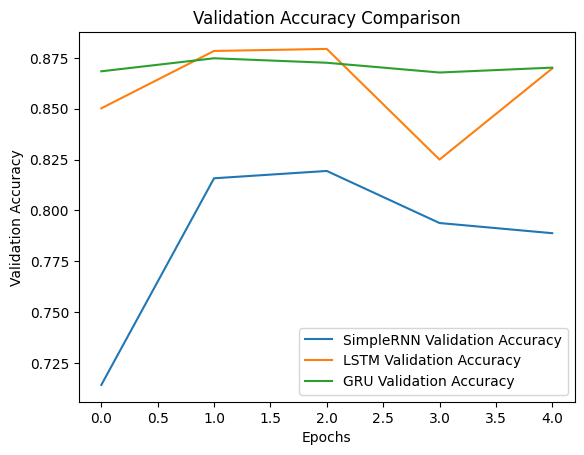

In [ ]:
# Plotting validation accuracy for each model
for model_name, history in zip(model_names, histories):
    plt.plot(history.history['val_accuracy'], label=f'{model_name} Validation Accuracy')

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()


**Displaying Test Metrics**

In [ ]:
# Display test loss and accuracy for each model
for model_name, test_loss, test_accuracy in zip(model_names, test_losses, test_accuracies):
    print(f'{model_name} Test loss: {test_loss}')
    print(f'{model_name} Test accuracy: {test_accuracy}')


SimpleRNN Test loss: 0.6026261448860168
SimpleRNN Test accuracy: 0.7928000092506409
LSTM Test loss: 0.43249350786209106
LSTM Test accuracy: 0.8590400218963623
GRU Test loss: 0.394130676984787
GRU Test accuracy: 0.8624799847602844
